# UMAPs restricted to mantispy hits

The per-cell UMAPs show one cloud, partly because most knockouts barely differ from non-targeting cells. Here we keep only knockouts that `mt.tl.map` calls as hits, plus non-targeting (NTC) cells. To avoid choosing hits and plotting on the same data, we call hits on half of the wells and plot cells from the other half. We repeat the plots at the level of guide and well averages, where noise is much lower. Everything is loaded from the shared MuData file, which also tests that file.

## Main findings

- **Restricting to hits helps, but cells still don't form separate clusters.** CTNNB1 and TGFBR2 now occupy different regions of each space, most clearly in cycleVI `z_other` and in DrVI without clock dimensions. The groups overlap, with no gaps between them.
- **Guide and well averages show the screen clearly.** CTNNB1 and TGFBR2 move away from controls in different directions in every space, and the two groups of control-like knockouts stay together. This is the level at which to judge the knockouts.
- **Protein separates TNFa at the level of single cells.** It is the only space where treated and untreated cells split into two groups. In the averages, DrVI also separates TNFa cleanly, and `z_other` loses most of that separation, as expected from the earlier results.
- **Hits depend on the space.** With 6 wells, `z_other` calls CTNNB1 and TGFBR2, cell paint calls TGFBR2, and DrVI and protein call nothing, although DrVI scores 0.75 to 0.78. Six wells give low power, so this table doesn't show that DrVI is worse.
- **Small separate islands need checking.** The protein, cell paint and `z_other` UMAPs each show a small island made mostly of TNFa cells. We haven't checked whether it comes from one well or an imaging artifact, or is a real response.

In the second column, controls are drawn first, so the knockouts can hide them. The plot shows where knockouts sit, and doesn't show how much they overlap with controls.


In [1]:
import anndata as ad
import mantispy as mt
import matplotlib.pyplot as plt
import mudata as md
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

mdata = md.read_h5mu("mu/cytos_multiomics_cycle.h5mu")
obs = mdata.obs.copy()
rna_mod, img = mdata["rna"], mdata["imaging"]
wells = obs["Well"].astype(str).values
conditions = obs["condition"].astype(str).values
targets = obs["target_gene"].astype(str).values
angle = np.radians(obs["cycle_position_deg"].values)
x = np.nan_to_num(np.clip(np.asarray(img.X), -10, 10))
selected, modality = img.var["selected"].values.astype(bool), img.var["modality"].astype(str).values


def well_centre(values):
    frame = pd.DataFrame(values)
    return (frame - frame.groupby(wells).transform("mean")).to_numpy()


drvi = np.asarray(rna_mod.obsm["X_drvi"])
d, c = well_centre(np.column_stack([np.sin(angle), np.cos(angle)])), well_centre(drvi)
clock_share = ((d @ np.linalg.lstsq(d, c, rcond=None)[0]) ** 2).sum(0) / (c**2).sum(0)
clock_dims = np.flatnonzero(clock_share > 0.1)
print("DrVI dimensions dropped as clock:", clock_dims, clock_share[clock_dims].round(2))
spaces = {
    "DrVI": drvi,
    "DrVI without clock dimensions": np.delete(drvi, clock_dims, axis=1),
    "cycleVI z_other": np.asarray(rna_mod.obsm["X_cyclevi_other"]),
    "Protein PCA": PCA(30, random_state=0).fit_transform(StandardScaler().fit_transform(x[:, selected & (modality == "protein")])),
    "Cell paint PCA": PCA(30, random_state=0).fit_transform(StandardScaler().fit_transform(x[:, selected & np.isin(modality, ["cell_paint", "shape"])])),
}
rng = np.random.default_rng(0)
hit_wells = np.concatenate([rng.permutation(np.unique(wells[conditions == c]))[:3] for c in np.unique(conditions)])
print("Wells used to call hits:", sorted(hit_wells))
is_hit_well = np.isin(wells, hit_wells)

DrVI dimensions dropped as clock: [ 0  5 31] [0.18 0.47 0.7 ]


Wells used to call hits: ['B1', 'C2', 'D1', 'E2', 'F1', 'F2']


## Which knockouts are hits?

`mt.tl.map` compares each knockout's guide and well profiles with those of non-targeting cells, within each TNFa condition. A knockout counts as a hit at corrected p below 0.05, using only the wells chosen for calling hits.

In [2]:
def profiles_of(values, mask):
    frame = pd.DataFrame({"Metadata_Plate": "Cytos-MPS_TNFa", "Metadata_Well": wells[mask], "Metadata_Guide": obs["guide"].astype(str).values[mask], "Metadata_Perturbation": targets[mask], "Metadata_Condition": conditions[mask], "Metadata_ImageID": obs["Metadata_ImageID"].astype(str).values[mask], "Metadata_ObjectType": "cell", "Metadata_ObjectNumber": obs["Cell"].astype(int).values[mask]})
    frame.index = [str(i) for i in range(len(frame))]
    a = ad.AnnData(X=np.asarray(values[mask], dtype=np.float32), obs=frame)
    mt.io.stamp(a, resolution="object", feature_kind="embedding")
    mt.pp.annotate_controls(a, negcon=["NTC"])
    return mt.tl.aggregate(a, by=("Metadata_Plate", "Metadata_Well", "Metadata_Guide"), func="mean")


calls = {}
for name, values in spaces.items():
    profile = profiles_of(values, is_hit_well)
    mt.tl.map(profile, mode="activity", batch="Metadata_Condition", null_size=1000)
    calls[name] = profile.uns["mantispy"]["map"].set_index("Metadata_Perturbation")
print(next(iter(calls.values())).columns.tolist())
scores = pd.DataFrame({k: v["score"] for k, v in calls.items()}).round(3)
qvalues = pd.DataFrame({k: v["qvalue"] for k, v in calls.items()}).round(4)
hits = {k: sorted(set(v.index[v["qvalue"] < 0.05]) - {"NTC"}) for k, v in calls.items()}
display(scores)
display(qvalues)
hits

['score', 'mean_normalized_average_precision', 'pvalue', 'qvalue', 'below_p', 'is_significant']


,DrVI,DrVI without clock dimensions,cycleVI z_other,Protein PCA,Cell paint PCA
Metadata_Perturbation,,,,,
CTNNB1,0.777,0.781,0.986,0.706,0.816
GSK3B,0.586,0.588,0.641,0.563,0.613
IL1R1,0.507,0.512,0.554,0.530,0.580
OR1I1,0.614,0.617,0.587,0.594,0.607
SMAD7,0.562,0.572,0.625,0.504,0.577
TGFBR2,0.754,0.765,0.975,0.722,0.952


,DrVI,DrVI without clock dimensions,cycleVI z_other,Protein PCA,Cell paint PCA
Metadata_Perturbation,,,,,
CTNNB1,0.3986,0.3626,0.003,0.999,0.1678
GSK3B,0.9990,0.9990,0.979,0.999,0.9441
IL1R1,0.9990,0.9990,0.979,0.999,0.9441
OR1I1,0.9990,0.9990,0.979,0.999,0.9441
SMAD7,0.9990,0.9990,0.979,0.999,0.9441
TGFBR2,0.3986,0.3626,0.003,0.999,0.0060


{'DrVI': [],
 'DrVI without clock dimensions': [],
 'cycleVI z_other': ['CTNNB1', 'TGFBR2'],
 'Protein PCA': [],
 'Cell paint PCA': ['TGFBR2']}

## Cells from hits only, on wells not used to call hits

Each row is one space, restricted to the knockouts called as a hit in any space, plus controls. Controls are NTC and OR1I1 together, because OR1I1 is an olfactory receptor that shouldn't be expressed in A549, and they are downsampled to the size of the largest hit so that they don't hide the knockouts. The first column shows all knockouts for comparison, using the same held-out wells.

Hits in any space: ['CTNNB1', 'TGFBR2']


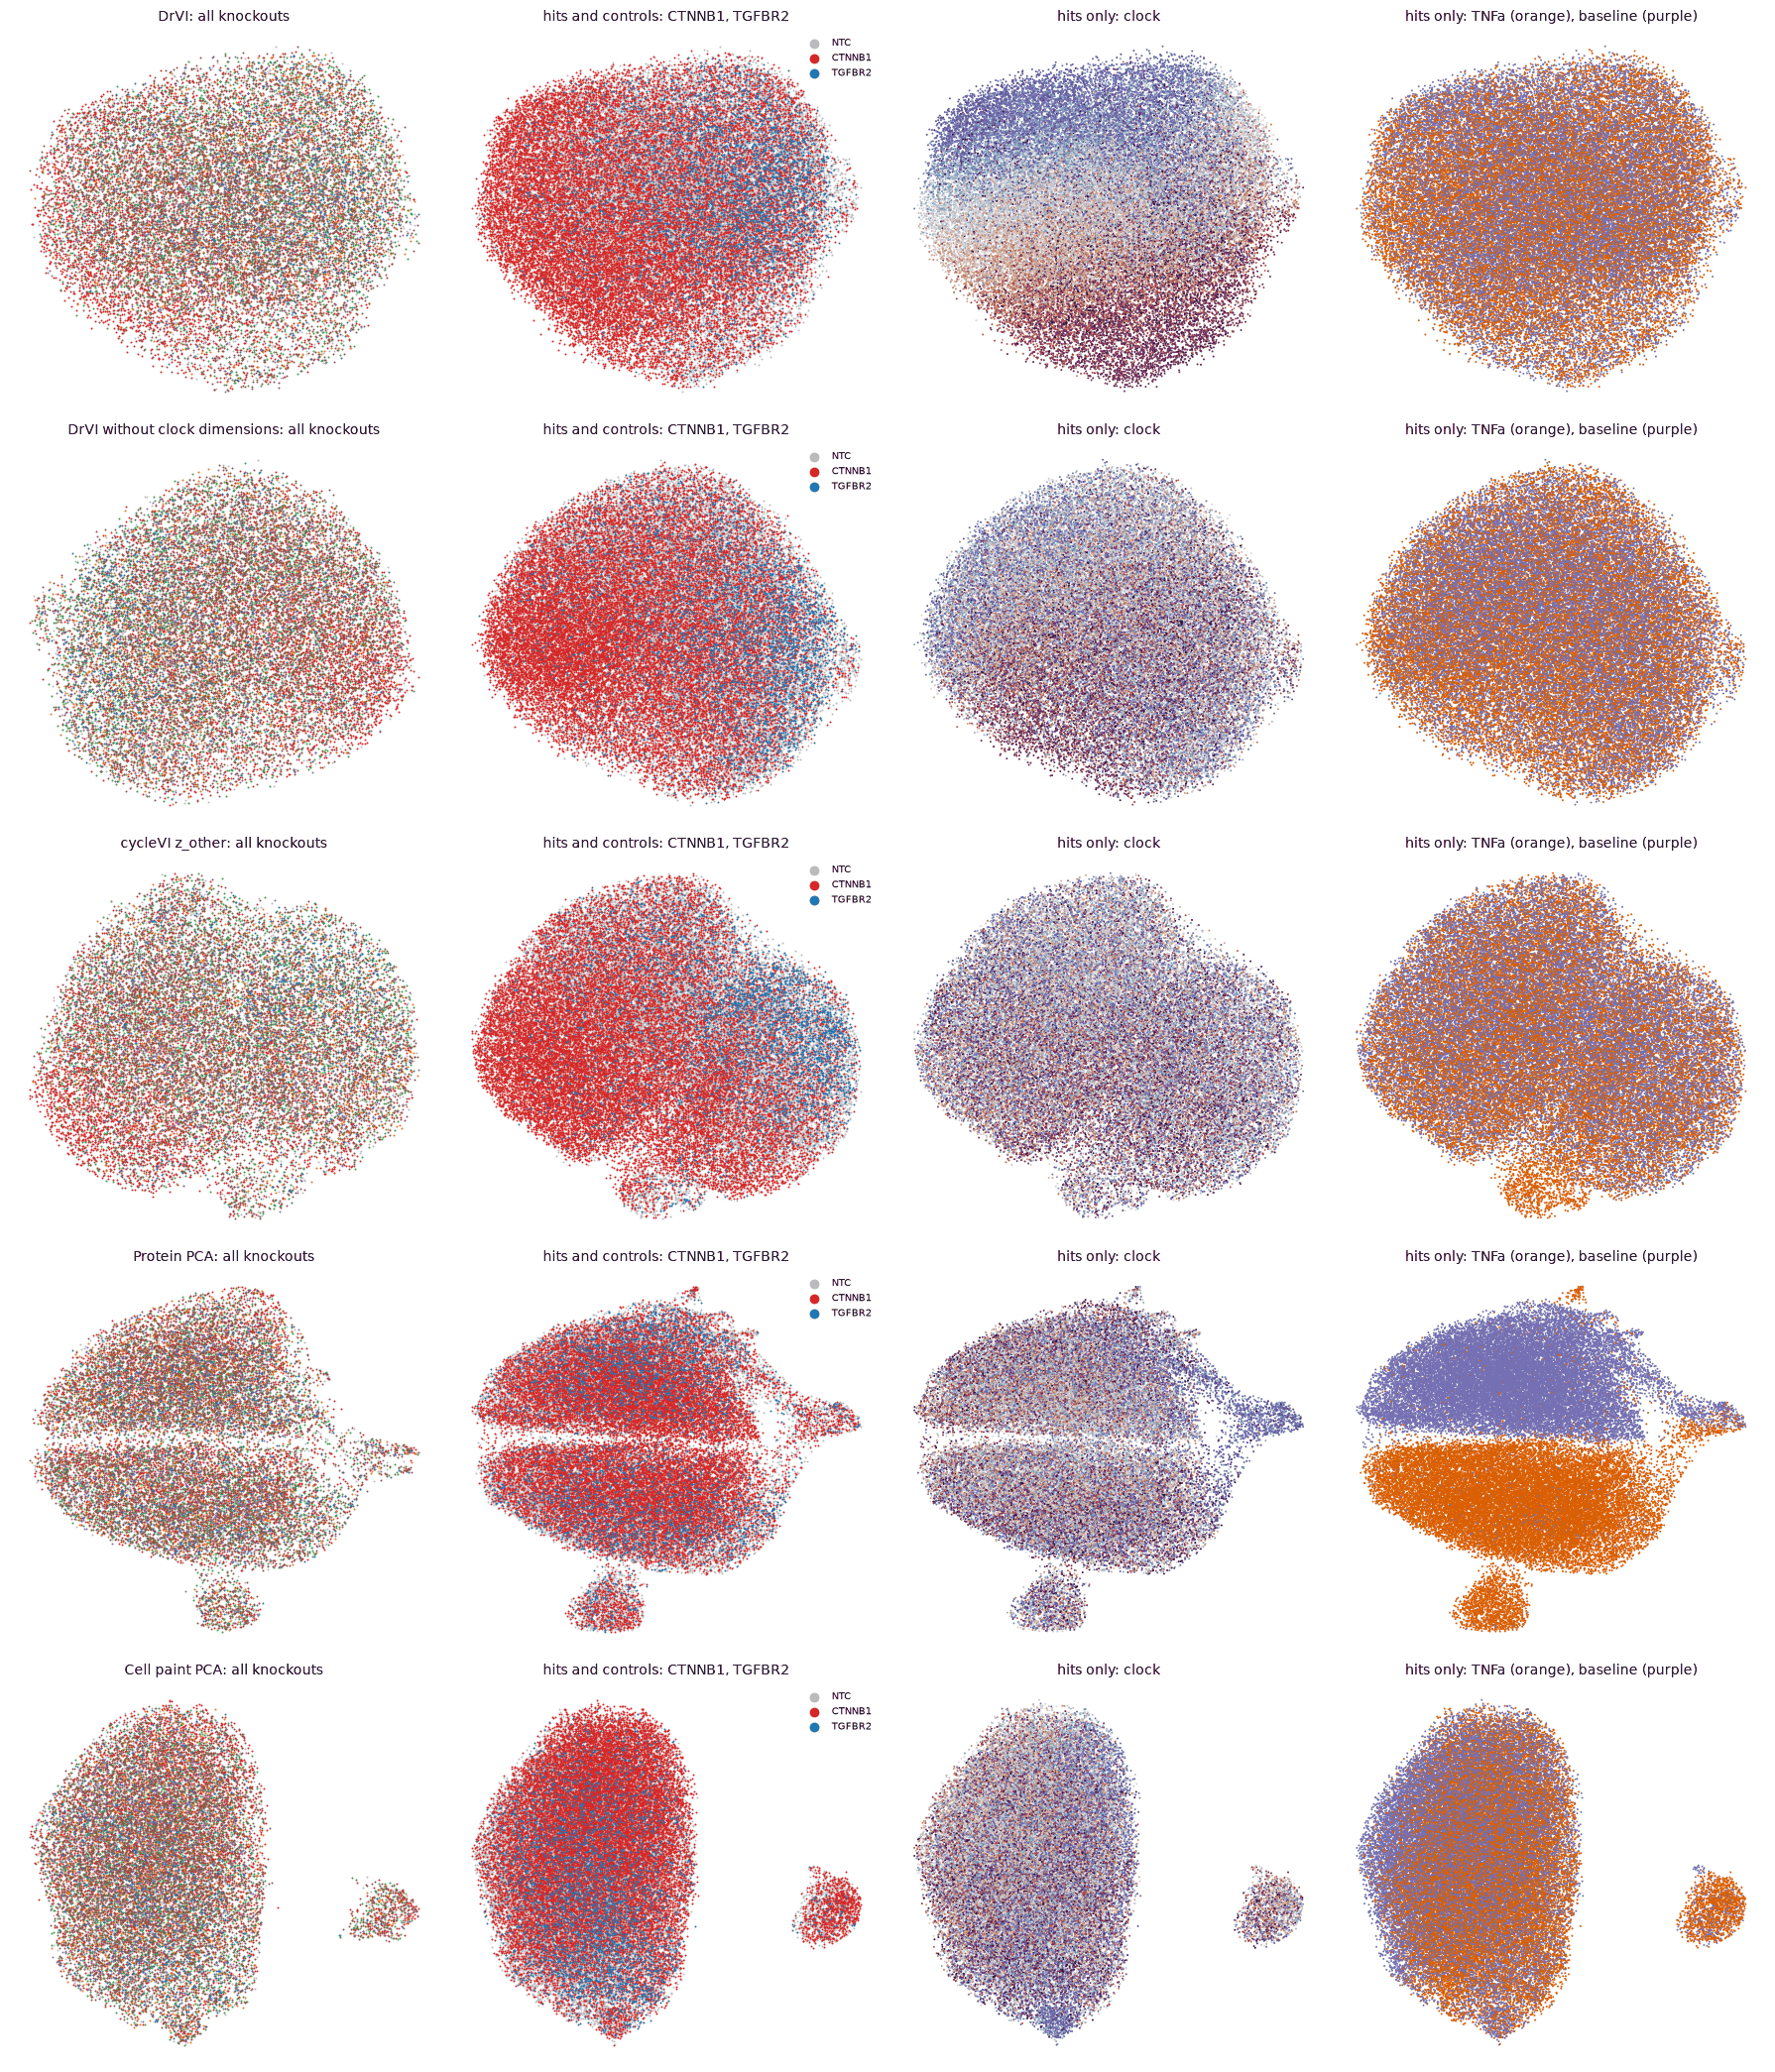

In [3]:
COLOURS = {"NTC": "#bbbbbb", "CTNNB1": "#d62728", "TGFBR2": "#1f77b4", "GSK3B": "#2ca02c", "SMAD7": "#9467bd", "IL1R1": "#ff7f0e", "OR1I1": "#8c564b"}


def layout(values):
    a = ad.AnnData(X=np.zeros((len(values), 1), dtype=np.float32), obsm={"X_rep": np.asarray(values, dtype=np.float32)})
    sc.pp.neighbors(a, use_rep="X_rep", transformer="sklearn")
    sc.tl.umap(a, random_state=0)
    return a.obsm["X_umap"]


def groups_plot(ax, xy, labels, title):
    for label in ["NTC"] + sorted(set(labels) - {"NTC"}):
        m = labels == label
        ax.scatter(*xy[m].T, s=2, linewidths=0, color=COLOURS[label], label=label, rasterized=True)
    ax.set_title(title, fontsize=10)
    ax.set(xticks=[], yticks=[])
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)


# ponytail: one hit list for every space, because six wells give low power in single spaces
hit_list = sorted(set().union(*hits.values()))
print("Hits in any space:", hit_list)
rows = list(spaces)
control = np.isin(targets, ["NTC", "OR1I1"])
fig, axes = plt.subplots(len(rows), 4, figsize=(18, 4.2 * len(rows)), squeeze=False)
for row, name in zip(axes, rows):
    values = spaces[name]
    held_out = np.flatnonzero(~is_hit_well)
    everything = rng.choice(held_out, 20_000, replace=False)
    xy = layout(values[everything])
    groups_plot(row[0], xy, targets[everything], f"{name}: all knockouts")
    keep = [np.flatnonzero((targets == h) & ~is_hit_well) for h in hit_list]
    size = max(len(k) for k in keep)
    pool = np.flatnonzero(control & ~is_hit_well)
    ntc = rng.choice(pool, min(size, len(pool)), replace=False)
    chosen = np.sort(np.concatenate(keep + [ntc]))
    xy = layout(values[chosen])
    groups_plot(row[1], xy, np.where(control[chosen], "NTC", targets[chosen]), f"hits and controls: {', '.join(hit_list)}")
    row[1].legend(markerscale=5, fontsize=7, frameon=False)
    order = rng.permutation(len(chosen))
    row[2].scatter(*xy[order].T, c=np.degrees(angle[chosen][order]), cmap="twilight", vmin=0, vmax=360, s=2, linewidths=0, rasterized=True)
    row[2].set_title("hits only: clock", fontsize=10)
    tnf = conditions[chosen][order] == "TNFa"
    row[3].scatter(*xy[order].T, c=np.where(tnf, "#d95f02", "#7570b3"), s=2, linewidths=0, rasterized=True)
    row[3].set_title("hits only: TNFa (orange), baseline (purple)", fontsize=10)
    for ax in row[2:]:
        ax.set(xticks=[], yticks=[])
        ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
plt.tight_layout()
plt.show()

## Guide and well averages

Each point is one guide in one well, averaged across its cells, from all wells. There are too few points for a UMAP, so we plot the first two principal components. Values are centred on each well's NTC cells, which removes differences between wells. If the screen has clear effects, CTNNB1 and TGFBR2 guides should form groups away from NTC and OR1I1. Well centring also removes the overall TNFa difference, so the second row keeps it by centring on the whole plate.

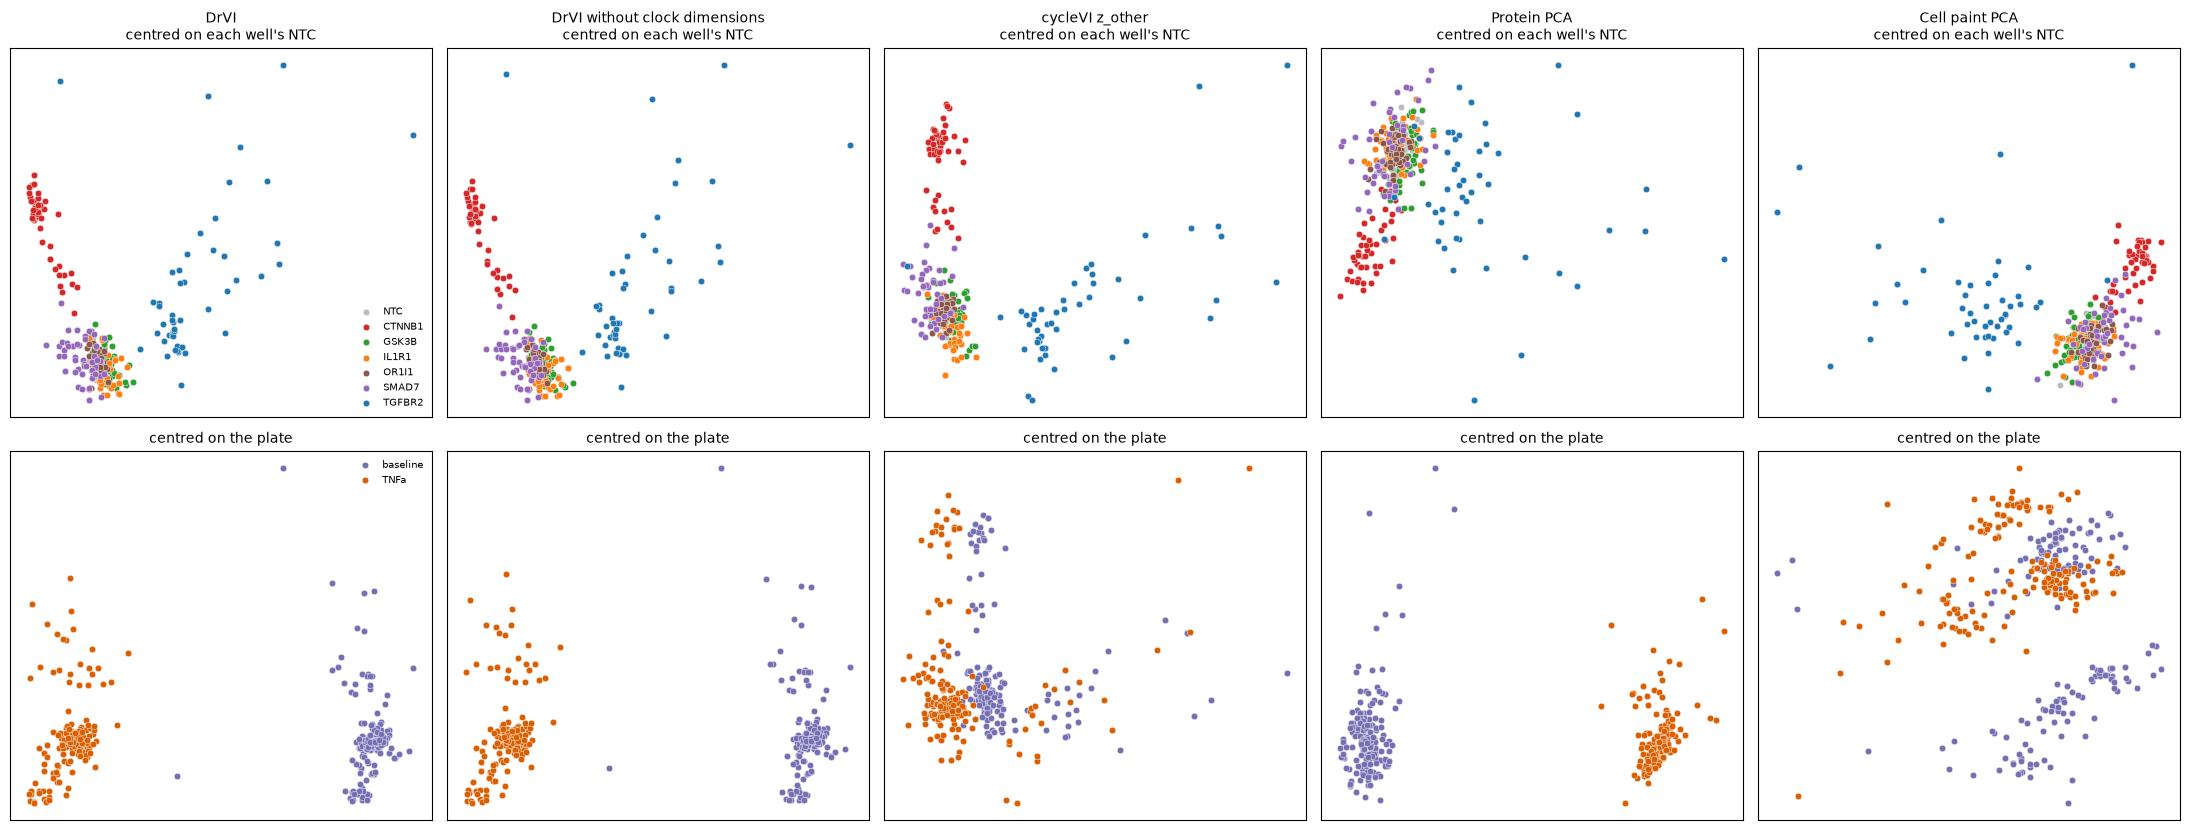

In [4]:
fig, axes = plt.subplots(2, len(spaces), figsize=(4.4 * len(spaces), 8.4))
frame_meta = pd.DataFrame({"well": wells, "guide": obs["guide"].astype(str).values, "target": targets, "condition": conditions})
for column, (name, values) in zip(axes.T, spaces.items()):
    table = pd.DataFrame(values).join(frame_meta)
    means = table.groupby(["well", "guide", "target", "condition"], observed=True).mean().reset_index()
    numeric = means.drop(columns=["well", "guide", "target", "condition"]).to_numpy()
    ntc = means.assign(**{}).loc[means["target"] == "NTC"].groupby("well").mean(numeric_only=True)
    centred = numeric - ntc.loc[means["well"]].to_numpy()
    coords = PCA(2, random_state=0).fit(centred)
    xy = coords.transform(centred)
    for label in ["NTC"] + sorted(set(means["target"]) - {"NTC"}):
        m = (means["target"] == label).values
        column[0].scatter(*xy[m].T, s=22, color=COLOURS[label], label=label, edgecolor="white", linewidth=0.3)
    column[0].set_title(f"{name}\ncentred on each well's NTC", fontsize=10)
    plate = PCA(2, random_state=0).fit_transform(numeric - numeric.mean(0))
    for label, colour in {"baseline": "#7570b3", "TNFa": "#d95f02"}.items():
        m = (means["condition"] == label).values
        column[1].scatter(*plate[m].T, s=22, color=colour, label=label, edgecolor="white", linewidth=0.3)
    column[1].set_title("centred on the plate", fontsize=10)
    for ax in column:
        ax.set(xticks=[], yticks=[])
axes[0, 0].legend(fontsize=7, frameon=False)
axes[1, 0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.show()